# How much of La Tigra can Tegucigalpa see?

**La Tigra National Park** rises right above the north-east edge of Tegucigalpa,
the capital. Its boundary and zones (core and buffer) come from ICF's protected
areas layer [@icf-areas-protegidas], and the city's built-up area from ICF's
ecosystems layer [@icf-ecosistemas].

The question for today's theme: **from the streets of the city, how much of the
park can you actually see?** A *viewshed* answers it: from an observer's eye,
every cell of the terrain is either in sight or hidden behind a ridge.

The terrain is the Copernicus GLO-30 elevation model [@copernicus-dem], and the
viewsheds are computed with GDAL's `gdal_viewshed` [@gdal], which has to be
installed on the system.

In [1]:
import subprocess
import sys
import tempfile
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib import patheffects
from matplotlib.colors import BoundaryNorm, LightSource, ListedColormap
import numpy as np
import pandas as pd
import rasterio
from rasterio.features import rasterize

sys.path.append("../..")  # maps/, for the shared scale bar and north arrow
from cartography import add_north_arrow, add_scale_bar

WFS = "https://geoserver.icf.gob.hn/icfpub/wfs"
CRS = 32616  # WGS 84 / UTM zone 16N, the ICF layers' own CRS, in metres


def read_layer(name: str, bbox: tuple | None = None) -> gpd.GeoDataFrame:
    """Read a layer from ICF's public WFS as GeoJSON, optionally within a bbox."""
    url = (
        f"{WFS}?service=WFS&version=2.0.0&request=GetFeature"
        f"&typeNames={name}&outputFormat=application/json"
    )
    if bbox:
        url += "&bbox=" + ",".join(map(str, bbox)) + f",EPSG:{CRS}"
    return gpd.read_file(url).to_crs(CRS)


protected = read_layer("areas_protegidas_gp")
tigra = protected[protected.nomb_ap == "La Tigra"]
print(tigra[["zona", "sub_zona", "area_ha"]].round(0).to_string(index=False))

ecosystems = read_layer("eco_vege_gp", bbox=(470000, 1540000, 500000, 1570000))
city = ecosystems[ecosystems.ecosistema == "Area urbana"].union_all()
print(f"Built-up area of Tegucigalpa: {city.area / 1e4:,.0f} ha")

           zona         sub_zona  area_ha
Amortiguamiento Manejo Intensivo   7702.0
         Núcleo      No definido   7693.0
Amortiguamiento Manejo Extensivo   8764.0


Built-up area of Tegucigalpa: 14,564 ha


/mnt/sda4/repos/30DaysChallenges/.venv/lib/python3.12/site-packages/pyogrio/raw.py:200: RuntimeWarning: Several features with id = 0 have been found. Altering it to be unique. This warning will not be emitted anymore for this layer
  return ogr_read(


## The terrain

The four 1° tiles of Copernicus GLO-30 around the city are read straight from
their public bucket, clipped to the city and the park plus a 10 km margin (so
the ridges around them can block the view), and reprojected to UTM at 30 m.

The model is a *surface* model: it includes the tops of trees and roofs. The
observer's eye sits 1.7 m above that surface, so the view is the one from a
rooftop or an open street, and in the park it is the canopy that is seen.

In [2]:
TILES = [
    f"Copernicus_DSM_COG_10_{lat}_00_{lon}_00_DEM"
    for lat in ("N13", "N14")
    for lon in ("W088", "W087")
]
BUCKET = "/vsicurl/https://copernicus-dem-30m.s3.amazonaws.com"
MARGIN = 10_000
CELL = 30

xmin, ymin, xmax, ymax = gpd.GeoSeries([city, tigra.union_all()]).total_bounds
extent = [
    round(v, -3) for v in (xmin - MARGIN, ymin - MARGIN, xmax + MARGIN, ymax + MARGIN)
]

work = Path(tempfile.mkdtemp())
dem_path = work / "dem.tif"
subprocess.run(
    ["gdalwarp", "-q", "-t_srs", f"EPSG:{CRS}", "-tr", str(CELL), str(CELL)]
    + ["-te", *map(str, extent), "-r", "bilinear"]
    + [f"{BUCKET}/{t}/{t}.tif" for t in TILES]
    + [str(dem_path)],
    check=True,
)
with rasterio.open(dem_path) as src:
    dem, transform, shape = src.read(1), src.transform, src.shape
print(f"DEM: {shape[1]} x {shape[0]} cells, {dem.min():.0f} to {dem.max():.0f} m")

DEM: 1600 x 1900 cells, 603 to 2328 m


## One viewshed per point of the city

The city is covered with observers on a 500 m grid, and each one gets its own
viewshed over the whole terrain. Adding them up gives, for every cell, **how
many points of the city see it**: a cumulative viewshed. Earth curvature and
refraction use GDAL's defaults.

In [3]:
SPACING = 500
EYE = 1.7  # metres above the surface

bx0, by0, bx1, by1 = city.bounds
xs, ys = np.meshgrid(np.arange(bx0, bx1, SPACING), np.arange(by0, by1, SPACING))
grid = gpd.GeoSeries(gpd.points_from_xy(xs.ravel(), ys.ravel()), crs=CRS)
observers = grid[grid.within(city)]
print(f"{len(observers)} observers")

seen_by = np.zeros(shape, np.uint16)
out = work / "viewshed.tif"
for p in observers:
    subprocess.run(
        ["gdal_viewshed", "-q", "-ox", str(p.x), "-oy", str(p.y), "-oz", str(EYE)]
        + ["-tz", "0", "-vv", "1", "-iv", "0", "-ov", "0", str(dem_path), str(out)],
        check=True,
    )
    with rasterio.open(out) as src:
        seen_by += src.read(1).astype(np.uint16)

581 observers


## How much of the park is in sight?

A cell counts as *in sight* when at least one point of the city sees it. The
share of points that see it says how common that view is across the city.

In [4]:
share = seen_by / len(observers)
zone_label = {"Núcleo": "core", "Amortiguamiento": "buffer"}

rows = []
for zone, part in [("whole park", tigra), *tigra.groupby("zona")]:
    inside = rasterize(part.geometry, out_shape=shape, transform=transform).astype(bool)
    rows.append(
        {
            "zone": zone_label.get(zone, zone),
            "area_ha": inside.sum() * CELL**2 / 1e4,
            "in sight": (seen_by[inside] > 0).mean(),
            "seen from 10%+ of the city": (share[inside] >= 0.10).mean(),
        }
    )
seen = pd.DataFrame(rows).set_index("zone")
seen.round(3)

,area_ha,in sight,seen from 10%+ of the city
zone,,,
whole park,24158.88,0.194,0.060
buffer,16467.57,0.165,0.017
core,7691.31,0.257,0.150


About a fifth of the park can be seen from somewhere in the city. The **core
zone**, the high ridge that faces Tegucigalpa, is the most visible part; most
of the buffer zone lies behind that ridge, to the north and east.

## The map

The same map in English and Spanish: only the text changes. Inside the park,
color shows the share of the city's points that see each cell.

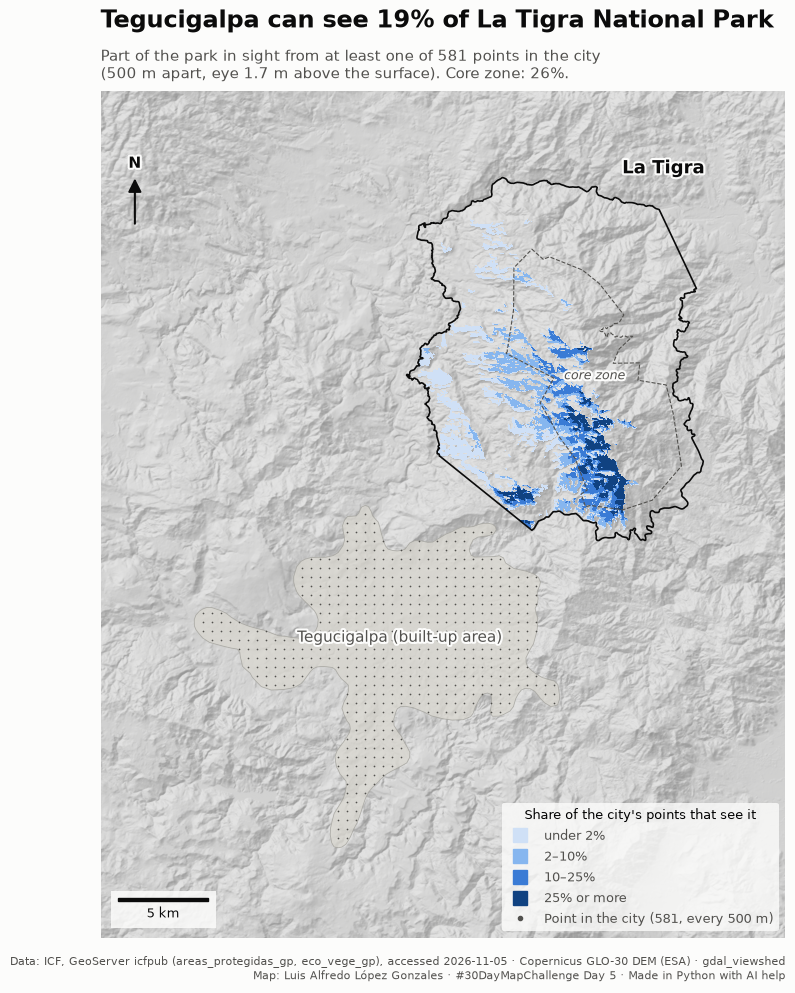

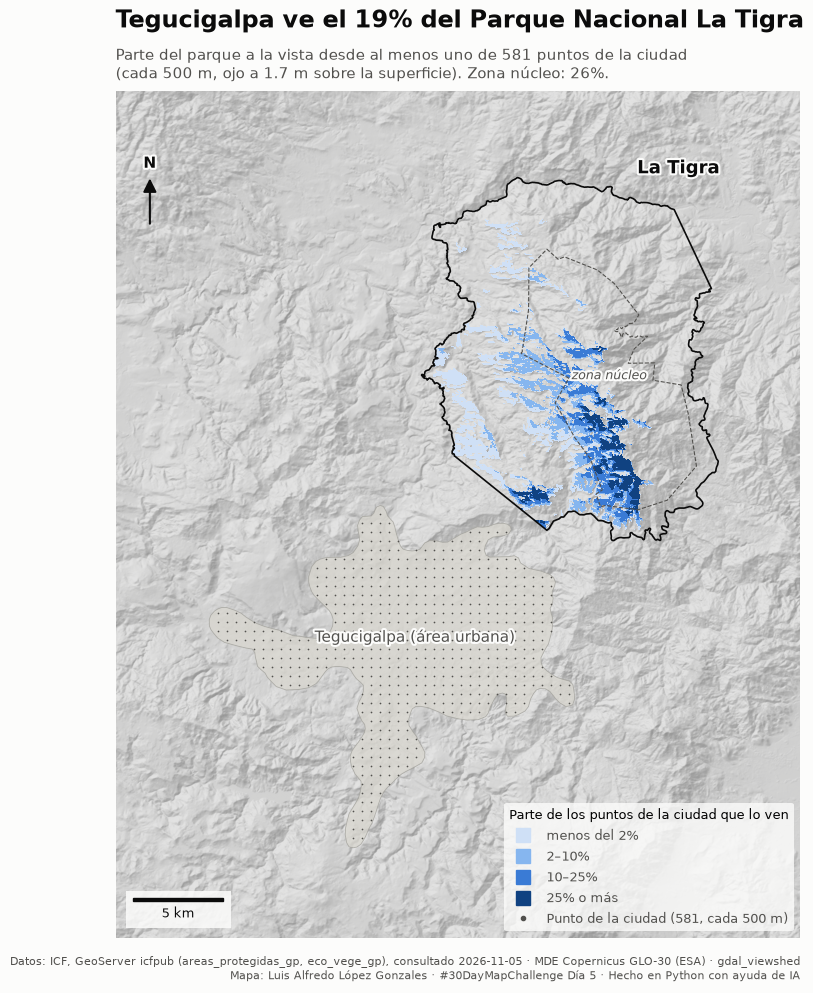

In [5]:
INK, INK_2, MUTED = "#0b0b0b", "#52514e", "#a3a29c"
SURFACE, CITY = "#fcfcfb", "#d9d7d0"
BINS = [0.0005, 0.02, 0.10, 0.25, 1.0001]
COLORS = ["#cfe0f6", "#86b6ef", "#3a7bd5", "#104281"]

relief = LightSource(azdeg=315, altdeg=45).hillshade(dem, vert_exag=2, dx=CELL, dy=CELL)
park_mask = rasterize(tigra.geometry, out_shape=shape, transform=transform).astype(bool)
in_park = np.ma.masked_where(~park_mask | (seen_by == 0), share)
core = tigra[tigra.zona == "Núcleo"]
xlim = (extent[0] + MARGIN / 2, extent[2] - MARGIN / 2)
ylim = (extent[1] + MARGIN / 2, extent[3] - MARGIN / 2)

whole = seen.loc["whole park", "in sight"]
core_seen = seen.loc["core", "in sight"]
TEXT = {
    "en": {
        "title": f"Tegucigalpa can see {whole:.0%} of La Tigra National Park",
        "subtitle": f"Part of the park in sight from at least one of {len(observers)} "
        f"points in the city\n(500 m apart, eye 1.7 m above the surface). "
        f"Core zone: {core_seen:.0%}.",
        "legend": "Share of the city's points that see it",
        "observers": f"Point in the city ({len(observers)}, every 500 m)",
        "bins": ["under 2%", "2–10%", "10–25%", "25% or more"],
        "city": "Tegucigalpa (built-up area)",
        "park": "La Tigra",
        "core": "core zone",
        "credits": "Data: ICF, GeoServer icfpub (areas_protegidas_gp, eco_vege_gp), "
        "accessed 2026-11-05 · Copernicus GLO-30 DEM (ESA) · gdal_viewshed\n"
        "Map: Luis Alfredo López Gonzales · #30DayMapChallenge Day 5 · "
        "Made in Python with AI help",
    },
    "es": {
        "title": f"Tegucigalpa ve el {whole:.0%} del Parque Nacional La Tigra",
        "subtitle": f"Parte del parque a la vista desde al menos uno de {len(observers)} "
        f"puntos de la ciudad\n(cada 500 m, ojo a 1.7 m sobre la superficie). "
        f"Zona núcleo: {core_seen:.0%}.",
        "legend": "Parte de los puntos de la ciudad que lo ven",
        "observers": f"Punto de la ciudad ({len(observers)}, cada 500 m)",
        "bins": ["menos del 2%", "2–10%", "10–25%", "25% o más"],
        "city": "Tegucigalpa (área urbana)",
        "park": "La Tigra",
        "core": "zona núcleo",
        "credits": "Datos: ICF, GeoServer icfpub (areas_protegidas_gp, eco_vege_gp), "
        "consultado 2026-11-05 · MDE Copernicus GLO-30 (ESA) · gdal_viewshed\n"
        "Mapa: Luis Alfredo López Gonzales · #30DayMapChallenge Día 5 · "
        "Hecho en Python con ayuda de IA",
    },
}

HALO = [patheffects.withStroke(linewidth=3, foreground=SURFACE)]


def draw_map(lang: str) -> plt.Figure:
    """Draw the visibility map with its text in `lang` ("en" or "es")."""
    text = TEXT[lang]
    fig, ax = plt.subplots(figsize=(10, 11), facecolor=SURFACE)
    ax.set_facecolor(SURFACE)
    img_extent = [extent[0], extent[2], extent[1], extent[3]]

    ax.imshow(relief, cmap="gray", vmin=-0.3, vmax=1.3, extent=img_extent, alpha=0.55)
    gpd.GeoSeries([city], crs=CRS).plot(
        ax=ax, color=CITY, alpha=0.8, edgecolor=MUTED, linewidth=0.6
    )
    observers.plot(ax=ax, color=INK_2, markersize=1.5, linewidth=0)
    ax.imshow(
        in_park,
        cmap=ListedColormap(COLORS),
        norm=BoundaryNorm(BINS, len(COLORS)),
        extent=img_extent,
        interpolation="nearest",
    )
    tigra.dissolve().boundary.plot(ax=ax, color=INK, linewidth=1.2)
    core.boundary.plot(ax=ax, color=INK_2, linewidth=0.8, linestyle="--")

    cx, cy = city.centroid.x, city.centroid.y
    ax.text(
        cx, cy, text["city"], ha="center", fontsize=11, color=INK_2, path_effects=HALO
    )
    px, py = tigra.union_all().bounds[2], tigra.union_all().bounds[3]
    ax.text(
        px,
        py,
        text["park"],
        ha="right",
        va="bottom",
        fontsize=13,
        fontweight="bold",
        color=INK,
        path_effects=HALO,
    )
    kx, ky = core.union_all().representative_point().coords[0]
    ax.text(
        kx,
        ky,
        text["core"],
        ha="center",
        fontsize=9,
        color=INK_2,
        style="italic",
        path_effects=HALO,
    )

    ax.text(
        0.0,
        1.075,
        text["title"],
        transform=ax.transAxes,
        fontsize=17,
        fontweight="bold",
        color=INK,
    )
    ax.text(
        0.0, 1.015, text["subtitle"], transform=ax.transAxes, fontsize=10.5, color=INK_2
    )

    handles = [
        plt.Line2D([], [], marker="s", ls="", ms=10, color=c, label=b)
        for c, b in zip(COLORS, text["bins"])
    ] + [
        plt.Line2D(
            [], [], marker="o", ls="", ms=3, color=INK_2, label=text["observers"]
        )
    ]
    ax.legend(
        handles=handles,
        title=text["legend"],
        loc="lower right",
        frameon=True,
        facecolor=SURFACE,
        edgecolor="none",
        fontsize=9.5,
        title_fontsize=9.5,
        labelcolor=INK_2,
    )
    ax.text(
        1.0,
        -0.02,
        text["credits"],
        transform=ax.transAxes,
        ha="right",
        va="top",
        fontsize=8,
        color=INK_2,
    )

    ax.set_xlim(xlim)
    ax.set_ylim(ylim)
    ax.set_axis_off()
    ax.set_aspect("equal")
    add_scale_bar(ax, loc="lower left", color=INK, background=SURFACE)
    add_north_arrow(ax, xy=(0.05, 0.9), color=INK, halo=SURFACE)
    return fig


for lang in TEXT:
    fig = draw_map(lang)
    fig.savefig(
        f"day05-sight-{lang}.png", dpi=200, bbox_inches="tight", facecolor=SURFACE
    )
plt.show()

## References

::: {#refs}
:::